In [1]:
import xgboost as xgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_pinball_loss
from datetime import datetime, timedelta

plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'

In [2]:
X_train = np.load('../../output/data_yipeng3/qrf/X_train.npy')
y_train = np.load('../../output/data_yipeng3/qrf/y_train.npy')
X_test = np.load('../../output/data_yipeng3/qrf/X_test.npy')
y_test = np.load('../../output/data_yipeng3/qrf/y_test.npy')
X_val = np.load('../../output/data_yipeng3/qrf/X_val.npy')
y_val = np.load('../../output/data_yipeng3/qrf/y_val.npy')

SLIDINGW_STEPS = 5
N_OUT_FEATS = y_train.shape[-1]
N_INP_FEATS = X_train.shape[-1]

y_train = y_train.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_train = X_train.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_val = y_val.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_val = X_val.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_test = y_test.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_test = X_test.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))

In [3]:
yipeng3_y = np.load('../../output/data_yipeng3/qrf/yipeng3_y.npy', allow_pickle=True)\
    .reshape((-1, 5*3))
yipeng3_x = np.load('../../output/data_yipeng3/qrf/yipeng3_x.npy', allow_pickle=True)\
    .reshape((-1, 5*20))

## Delta COG

In [4]:
best_hyper = {
    'n_estimators': 128,
    'max_depth': 4,
    'eta': 0.05,
    'subsample': 0.6
}

In [5]:
var_num = 0

model_low = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.025,
    device='gpu',
    **best_hyper
)

model_high = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.975,
    device='gpu',
    **best_hyper
)

model_low.fit(X_train, y_train[:, var_num])
model_high.fit(X_train, y_train[:, var_num])

yipeng3_low = model_low.predict(yipeng3_x)
yipeng3_high = model_high.predict(yipeng3_x)

y_low = model_low.predict(X_val)
y_high = model_high.predict(X_val)

val_mmsis = np.load('../../output/data_yipeng3/qrf/val-mmsis.npy', allow_pickle=True)
val_days = np.load('../../output/data_yipeng3/qrf/val-days.npy', allow_pickle=True)

in_pi_mask = (y_val[:, var_num] > y_low) & (y_val[:, var_num] < y_high)

group_results = {}
for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix] )

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.mean(pi_masks)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means
    })

df = pd.DataFrame(df)
print( np.quantile( df['delta_cog'], 0.05 ) )

np.mean( (yipeng3_y[:, var_num] < yipeng3_high[:]) & (yipeng3_y[:, var_num] > yipeng3_low[:]) )

0.8531512605042016


/home/lukas/straipsnis/qrf-venv/lib/python3.12/site-packages/xgboost/core.py:553: UserWarning: [22:18:29] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


np.float64(0.9359605911330049)

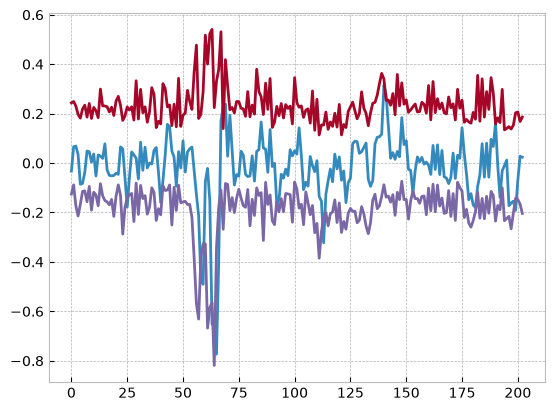

In [6]:
plt.plot(yipeng3_y[:, var_num])
plt.plot(yipeng3_high)
plt.plot(yipeng3_low)

In [7]:
best_hyper = {
    'n_estimators': 128,
    'max_depth': 4,
    'eta': 0.05,
    'subsample': 0.6
}

In [8]:
var_num = 1

model_low = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.025,
    device='gpu',
    **best_hyper
)

model_high = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.975,
    device='gpu',
    **best_hyper
)

model_low.fit(X_train, y_train[:, var_num])
model_high.fit(X_train, y_train[:, var_num])

yipeng3_low = model_low.predict(yipeng3_x)
yipeng3_high = model_high.predict(yipeng3_x)

y_low = model_low.predict(X_val)
y_high = model_high.predict(X_val)

val_mmsis = np.load('../../output/data_yipeng3/qrf/val-mmsis.npy', allow_pickle=True)
val_days = np.load('../../output/data_yipeng3/qrf/val-days.npy', allow_pickle=True)

in_pi_mask = (y_val[:, var_num] > y_low) & (y_val[:, var_num] < y_high)

group_results = {}
for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix] )

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.mean(pi_masks)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_dif': means
    })

df = pd.DataFrame(df)
print( np.quantile( df['delta_dif'], 0.05 ) )

np.mean( (yipeng3_y[:, var_num] < yipeng3_high[:]) & (yipeng3_y[:, var_num] > yipeng3_low[:]) )

0.8571428571428571


np.float64(0.9113300492610837)

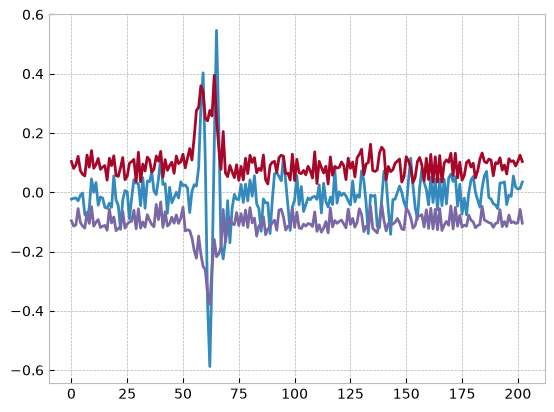

In [9]:
plt.plot(yipeng3_y[:, var_num])
plt.plot(yipeng3_high)
plt.plot(yipeng3_low)

In [10]:
best_hyper = {
    'n_estimators': 128,
    'max_depth': 4,
    'eta': 0.05,
    'subsample': 1.0
}

In [11]:
var_num = 2

model_low = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.025,
    device='gpu',
    **best_hyper
)

model_high = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.975,
    device='gpu',
    **best_hyper
)

model_low.fit(X_train, y_train[:, var_num])
model_high.fit(X_train, y_train[:, var_num])

yipeng3_low = model_low.predict(yipeng3_x)
yipeng3_high = model_high.predict(yipeng3_x)

y_low = model_low.predict(X_val)
y_high = model_high.predict(X_val)

val_mmsis = np.load('../../output/data_yipeng3/qrf/val-mmsis.npy', allow_pickle=True)
val_days = np.load('../../output/data_yipeng3/qrf/val-days.npy', allow_pickle=True)

in_pi_mask = (y_val[:, var_num] > y_low) & (y_val[:, var_num] < y_high)

group_results = {}
for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix] )

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.mean(pi_masks)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means
    })

df = pd.DataFrame(df)
thresh_dif =  np.quantile( df['delta_cog'], 0.05 )
print(thresh_dif)

np.mean( (yipeng3_y[:75, var_num] < yipeng3_high[:75]) & (yipeng3_y[:75, var_num] > yipeng3_low[:75]) )

0.8639328063241107


np.float64(0.84)

In [12]:
y_low = model_low.predict(X_test)
y_high = model_high.predict(X_test)

test_mmsis = np.load('../../output/data_yipeng3/qrf/test-mmsis.npy', allow_pickle=True)
test_days = np.load('../../output/data_yipeng3/qrf/test-days.npy', allow_pickle=True)

in_pi_mask = (y_test[:, var_num] > y_low) & (y_test[:, var_num] < y_high)

group_results = {}
for ix, (mmsi, day) in enumerate(zip(test_mmsis, test_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix] )

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.mean(pi_masks)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'dif': means
    })

df = pd.DataFrame(df)
np.mean(df['dif'] < thresh_dif)

np.float64(0.06635071090047394)

In [13]:
timestamps_yipeng3 = pd.date_range(
    start=datetime(2024,11,18,2,30),
    end=datetime(2024,11,19,0,0),
    periods=yipeng3_y.shape[0]
)

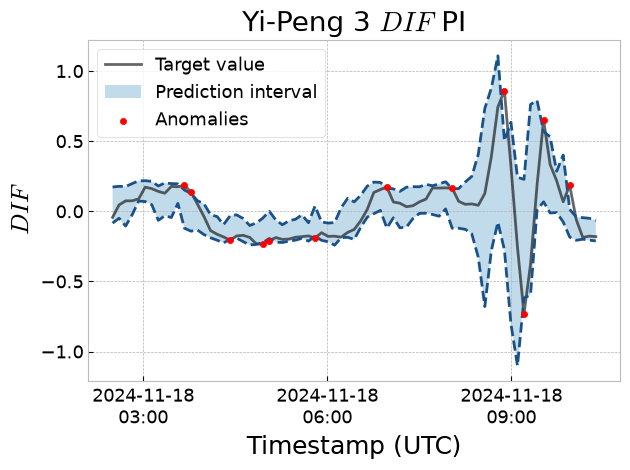

In [14]:
y_flat = yipeng3_y[:75, 2]
y_low = yipeng3_low[:75]
y_high = yipeng3_high[:75]
timestamps_yipeng3 = list(timestamps_yipeng3)[:75]

anomalies_x = []
anomalies_y = []
for i in range(y_flat.shape[0]):

    if y_flat[i] < y_low[i]:
        anomalies_x.append( timestamps_yipeng3[i] )
        anomalies_y.append( y_flat[i] )

    elif y_flat[i] > y_high[i]:
        anomalies_x.append( timestamps_yipeng3[i] )
        anomalies_y.append( y_flat[i] )

plt.plot(timestamps_yipeng3, y_flat, label = "Target value", color='black', alpha=0.6)
plt.plot(timestamps_yipeng3, y_low, color='#185288', linestyle='--')
plt.plot(timestamps_yipeng3, y_high, color="#185288", linestyle='--')

ticks=[datetime(2024,11,18,0,0) + timedelta(hours=x) for x in range(0, 30, 3)]
labels=[tick.strftime('%Y-%m-%d\n%H:%M') for tick in ticks]
plt.xticks(
    ticks=ticks,
    labels=labels
)
plt.tick_params(axis='both', which='both', labelsize=13)

plt.xlabel('Timestamp (UTC)', size=18)
plt.ylabel(r'$DIF$', size=18)
plt.title(r'Yi-Peng 3 $DIF$ PI', size=20)

plt.fill_between(x=timestamps_yipeng3, y1=y_low, y2=y_high, alpha=0.3, label='Prediction interval')
plt.scatter(anomalies_x, anomalies_y, color='red', s=20, zorder=5, label='Anomalies')
plt.legend(fontsize=13)

plt.tight_layout()
plt.savefig("../images/dif-xgboost-yipeng3.png", dpi=750)

plt.show()

In [15]:
(75-len(anomalies_y))/75

0.84

In [16]:
import shap

features = [
    'SPEED', 'COURSE', 'currentSpeed', 'gust', 'swellHeight',
    'waveHeight', 'windSpeed', 'dif', 'COURSE-dif', 'delta_dif',
    'COURSE_vec_x', 'COURSE_vec_y', 'currentDirection_vec_x',
    'currentDirection_vec_y', 'swellDirection_vec_x',
    'swellDirection_vec_y', 'waveDirection_vec_x', 'waveDirection_vec_y',
    'windDirection_vec_x', 'windDirection_vec_y'
]
feature_names = [
    'SOG', 'COG', 'CurrentSpeed', 'Gust', 'SwellHeight',
    'WaveHeight', 'WindSpeed', 'DIF', r'\Delta COG',
    r'\Delta DIF', 'COG_x', 'COG_y', 'CurrentDirection_x',
    'CurrentDirection_y', 'SwellDirection_x', 'SwellDirection_y',
    'WaveDirection_x', 'WaveDirection_y', ' WindDirection_x', 'WindDirection_y'
]

feature_names = [
    rf'${col}(t-{t})$'
    for t in range(0,25,5)
    for col in feature_names
]

explainer_high = shap.TreeExplainer(model_high, feature_names=feature_names)
explainer_low = shap.TreeExplainer(model_low, feature_names=feature_names)

shap_high = explainer_high(yipeng3_x)
shap_low = explainer_low(yipeng3_x)

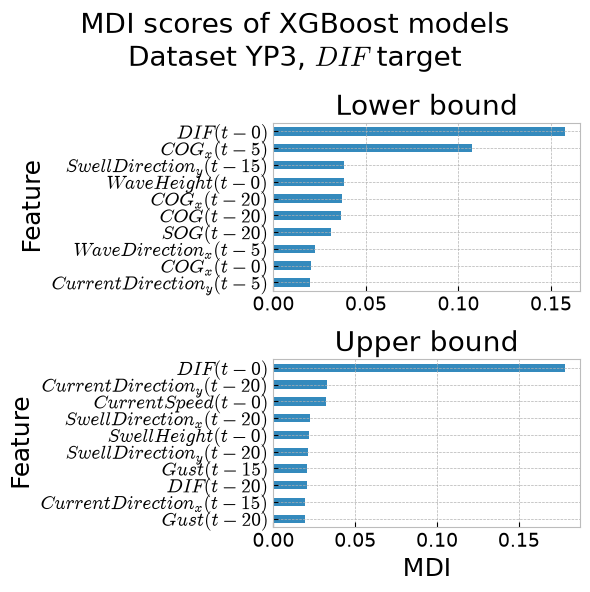

In [19]:
fig, axs = plt.subplots(nrows=2, figsize=(6,6))
fig.suptitle('MDI scores of XGBoost models\nDataset YP3, $DIF$ target', size=20)

df_imp = pd.DataFrame({
    'Feature': feature_names,
    'Feature importance': model_low.feature_importances_
})
df_imp\
    .set_index(keys='Feature')\
    .sort_values(by='Feature importance', ascending=True)\
    .tail(10)\
    .plot.barh(ax=axs[0])

# Source - https://stackoverflow.com/a/26845924
# Posted by naitsirhc, modified by community. See post 'Timeline' for change history
# Retrieved 2026-09-23, License - CC BY-SA 4.0
axs[0].get_legend().remove()
axs[0].tick_params(axis='both', labelsize=14)
axs[0].set_ylabel('Feature', size=18)
axs[0].set_title('Lower bound', size=20)

df_imp = pd.DataFrame({
    'Feature': feature_names,
    'Feature importance': model_high.feature_importances_
})
df_imp\
    .set_index(keys='Feature')\
    .sort_values(by='Feature importance', ascending=True)\
    .tail(10)\
    .plot.barh(ax=axs[1])

# Source - https://stackoverflow.com/a/26845924
# Posted by naitsirhc, modified by community. See post 'Timeline' for change history
# Retrieved 2026-09-23, License - CC BY-SA 4.0
axs[1].get_legend().remove()
axs[1].tick_params(axis='both', labelsize=14)
axs[1].set_ylabel('Feature', size=18)
axs[1].set_xlabel('MDI', size=18)
axs[1].set_title('Upper bound', size=20)

plt.tight_layout()
plt.savefig('mdi-scores-xgboost-yp3.png', dpi=750)

In [20]:
df_imp = pd.DataFrame({
    'Feature': feature_names,
    'Feature importance': model_low.feature_importances_
})
df_imp\
    .set_index(keys='Feature')\
    .sort_values(by='Feature importance', ascending=True)\
    .tail(10)

,Feature importance
Feature,
$CurrentDirection_y(t-5)$,0.019976
$COG_x(t-0)$,0.020366
$WaveDirection_x(t-5)$,0.022583
$SOG(t-20)$,0.031074
$COG(t-20)$,0.036678
$COG_x(t-20)$,0.037287
$WaveHeight(t-0)$,0.038076
$SwellDirection_y(t-15)$,0.038165
$COG_x(t-5)$,0.107283


In [22]:
0.157783 / 0.038165

4.134232935936067

In [21]:

df_imp = pd.DataFrame({
    'Feature': feature_names,
    'Feature importance': model_high.feature_importances_
})
df_imp\
    .set_index(keys='Feature')\
    .sort_values(by='Feature importance', ascending=True)\
    .tail(10)

,Feature importance
Feature,
$Gust(t-20)$,0.019037
$CurrentDirection_x(t-15)$,0.019558
$DIF(t-20)$,0.020460
$Gust(t-15)$,0.020568
$SwellDirection_y(t-20)$,0.021418
$SwellHeight(t-0)$,0.021761
$SwellDirection_x(t-20)$,0.022508
$CurrentSpeed(t-0)$,0.031893
$CurrentDirection_y(t-20)$,0.032979


In [23]:
0.178426 / 0.032979

5.41029139755602

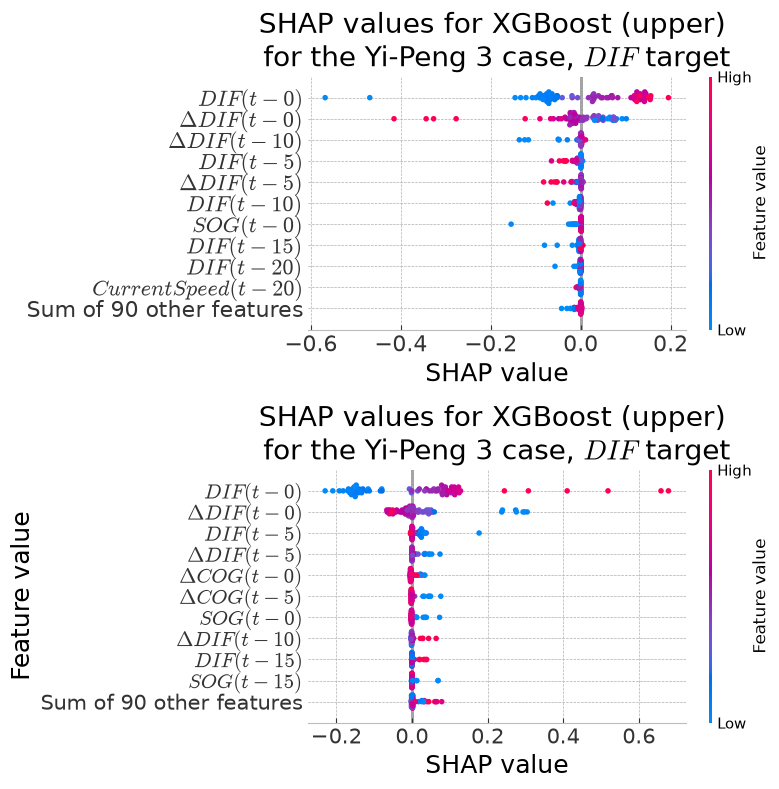

In [ ]:
fig, axs = plt.subplots(2, 1)
plt.sca(axs[0])
shap.plots.beeswarm(shap_low[:75], show=False, plot_size=(8,8), max_display=11)

axs[0].set_title('SHAP values for XGBoost (upper) \nfor the Yi-Peng 3 case, $DIF$ target', size=20)
axs[0].tick_params(axis='both', labelsize=16)
axs[0].set_xlabel('SHAP value', size=18)

# https://github.com/shap/shap/issues/594#issuecomment-1206481300
cbar = plt.gcf().axes[1]
cbar.tick_params(labelsize=15)
cbar.set_ylabel("Feature value", fontsize=18)

plt.sca(axs[1])
shap.plots.beeswarm(shap_high[:75], show=False, plot_size=(8,8), max_display=11)

axs[1].set_title('SHAP values for XGBoost (upper) \nfor the Yi-Peng 3 case, $DIF$ target', size=20)
axs[1].tick_params(axis='both', labelsize=16)
axs[1].set_xlabel('SHAP value', size=18)

# https://github.com/shap/shap/issues/594#issuecomment-1206481300
cbar = plt.gcf().axes[1]
cbar.tick_params(labelsize=15)
cbar.set_ylabel("Feature value", fontsize=18)

plt.tight_layout()
plt.savefig('shap-values-yipeng3.png', dpi=750)
plt.show()

# This code is **adapted** from `https://github.com/amaa11/NMR`

In [24]:
# from https://github.com/amaa11/NMR
X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame( yipeng3_x, columns=feature_names)
y_train_dif = y_train[:, 2]

dicts = dict()
m = 0
MPM_list = []

while X_train_df.shape[1] != 1:

    MPM = 0
    NF = X_train_df.shape[1]
    for j in range(1, NF, 2):
        summ = NF-j
        MPM = MPM+summ
    MPM = MPM*2
    MPM_list.append(MPM)
    #print('MPM :', MPM)
    
    ITER_NUMBER = X_train_df.shape[1]                          ## number of features in each iteration
    model_high = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.975,
        device='gpu',
        **best_hyper
    )
    model_high.fit(X_train_df, y_train_dif)                      ## fit the data to the model
    ypred_test = model_high.predict (X_test_df)                             ## predict test data
    
    # fit shap
    explainer = shap.TreeExplainer(model_high)

    # apply shap to test data
    shap_values = explainer.shap_values(X_test_df)
    
    # the follwoing steps to represents the SHAP outcome (informative predictors) as datafram
    vals= np.abs(shap_values).mean(0)
    feature_importance = pd.DataFrame(list(zip(X_train_df.columns,vals)),columns=['Features','feature_importance_vals'])
    feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
    feature_importance.reset_index(inplace=True, drop=True)
    feature_importance.index = np.arange(1, len(feature_importance) + 1)
    #print(feature_importance)
    FEATURES = feature_importance[['Features']]
    #print(FEATURES)
    for i in range(FEATURES.shape[0]):
        #print(FEATURES.iloc[i]['Features'], end = " ")
        #print(FEATURES.iloc[i].name, end = " ")
        #for key in dicts:
        if FEATURES.iloc[i]['Features'] in dicts:
            dicts[FEATURES.iloc[i]['Features']].append(FEATURES.iloc[i].name + m)
        else:
            dicts[FEATURES.iloc[i]['Features']] = [FEATURES.iloc[i].name + m]
    
    m = m+1
    # identify the most informative predictor
    Top_feature = feature_importance.iloc[0]['Features']
    
    # remove the most informative predictor from train and test data
    X_train_df.drop([Top_feature], axis=1, inplace=True)
    X_train_df.reset_index(inplace=True, drop=True)
    X_test_df.drop([Top_feature], axis=1, inplace=True)
    X_test_df.reset_index(inplace=True, drop=True)

MPM_list.pop(0)

lenOfLists=len(dicts)
#function to add item at index=len ... append item
def add_item_to_dict(my_dict, key, value):
    my_dict[len(my_dict)] = [key,value]

    
sorted_dict = {}

for index in range(1,lenOfLists):
    for key, value in dicts.items():
        if len(value)==index:
            add_item_to_dict(sorted_dict,key,value)

#calculate sum of changes
sumOfChanges={}
#first is zero
add_item_to_dict(sumOfChanges,sorted_dict[0][0],0)

for index in range(1,lenOfLists-1):  
    key=sorted_dict[index][0]
    soc=0
    for t in range(index,lenOfLists):        
        soc+=abs(sorted_dict[t][1][index]-sorted_dict[t][1][index-1])
        #print(sorted_dict[t][1][index],sorted_dict[t][1][index-1],(sorted_dict[t][1][index]-sorted_dict[t][1][index-1]))
    add_item_to_dict(sumOfChanges,key,soc)
    #print(soc,'----') 
#last is same to last -1
add_item_to_dict(sumOfChanges,sorted_dict[lenOfLists-1][0],sumOfChanges[lenOfLists-2][1])
#print(sorted_dict)
#print(sumOfChanges)
sumOfChanges.popitem()
first_key = next(iter(sumOfChanges))
del sumOfChanges[first_key]
rates = []
ite=0
for key, value in sumOfChanges.items():    
    rates.append(value[1]/MPM_list[ite])
    ite=ite+1
#print(rates)
print("NMR value : ", round(np.mean(rates), 3))

NMR value :  0.353


In [26]:
# from https://github.com/amaa11/NMR
X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame( yipeng3_x, columns=feature_names)
y_train_dif = y_train[:, 2]

dicts = dict()
m = 0
MPM_list = []

while X_train_df.shape[1] != 1:

    MPM = 0
    NF = X_train_df.shape[1]
    for j in range(1, NF, 2):
        summ = NF-j
        MPM = MPM+summ
    MPM = MPM*2
    MPM_list.append(MPM)
    #print('MPM :', MPM)
    
    ITER_NUMBER = X_train_df.shape[1]                          ## number of features in each iteration
    model_low = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.025,
        device='gpu',
        **best_hyper
    )
    model_high.fit(X_train_df, y_train_dif)                      ## fit the data to the model
    ypred_test = model_high.predict (X_test_df)                             ## predict test data
    
    # fit shap
    explainer = shap.TreeExplainer(model_high)

    # apply shap to test data
    shap_values = explainer.shap_values(X_test_df)
    
    # the follwoing steps to represents the SHAP outcome (informative predictors) as datafram
    vals= np.abs(shap_values).mean(0)
    feature_importance = pd.DataFrame(list(zip(X_train_df.columns,vals)),columns=['Features','feature_importance_vals'])
    feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
    feature_importance.reset_index(inplace=True, drop=True)
    feature_importance.index = np.arange(1, len(feature_importance) + 1)
    #print(feature_importance)
    FEATURES = feature_importance[['Features']]
    #print(FEATURES)
    for i in range(FEATURES.shape[0]):
        #print(FEATURES.iloc[i]['Features'], end = " ")
        #print(FEATURES.iloc[i].name, end = " ")
        #for key in dicts:
        if FEATURES.iloc[i]['Features'] in dicts:
            dicts[FEATURES.iloc[i]['Features']].append(FEATURES.iloc[i].name + m)
        else:
            dicts[FEATURES.iloc[i]['Features']] = [FEATURES.iloc[i].name + m]
    
    m = m+1
    # identify the most informative predictor
    Top_feature = feature_importance.iloc[0]['Features']
    
    # remove the most informative predictor from train and test data
    X_train_df.drop([Top_feature], axis=1, inplace=True)
    X_train_df.reset_index(inplace=True, drop=True)
    X_test_df.drop([Top_feature], axis=1, inplace=True)
    X_test_df.reset_index(inplace=True, drop=True)

MPM_list.pop(0)

lenOfLists=len(dicts)
#function to add item at index=len ... append item
def add_item_to_dict(my_dict, key, value):
    my_dict[len(my_dict)] = [key,value]

    
sorted_dict = {}

for index in range(1,lenOfLists):
    for key, value in dicts.items():
        if len(value)==index:
            add_item_to_dict(sorted_dict,key,value)

#calculate sum of changes
sumOfChanges={}
#first is zero
add_item_to_dict(sumOfChanges,sorted_dict[0][0],0)

for index in range(1,lenOfLists-1):  
    key=sorted_dict[index][0]
    soc=0
    for t in range(index,lenOfLists):        
        soc+=abs(sorted_dict[t][1][index]-sorted_dict[t][1][index-1])
        #print(sorted_dict[t][1][index],sorted_dict[t][1][index-1],(sorted_dict[t][1][index]-sorted_dict[t][1][index-1]))
    add_item_to_dict(sumOfChanges,key,soc)
    #print(soc,'----') 
#last is same to last -1
add_item_to_dict(sumOfChanges,sorted_dict[lenOfLists-1][0],sumOfChanges[lenOfLists-2][1])
#print(sorted_dict)
#print(sumOfChanges)
sumOfChanges.popitem()
first_key = next(iter(sumOfChanges))
del sumOfChanges[first_key]
rates = []
ite=0
for key, value in sumOfChanges.items():    
    rates.append(value[1]/MPM_list[ite])
    ite=ite+1
#print(rates)
print("NMR value : ", round(np.mean(rates), 3))

NMR value :  0.353
